# Ejemplo R - Iris

In [2]:
# Cargar librerías
library(caret)
library(rpart)
library(rpart.plot)
library(dplyr)
library(ggplot2)

In [3]:
# 1. Cargar el dataset iris
data(iris)

In [4]:
# 2. Verificar si hay datos faltantes
cat("Valores faltantes en el dataset:", sum(is.na(iris)), "\n")

Valores faltantes en el dataset: 0 


In [5]:
# 3. Dividir en entrenamiento y test con igual proporción de clases
set.seed(123)
trainIndex <- createDataPartition(iris$Species, p = 0.7, list = FALSE)
iris_train <- iris[trainIndex, ]
iris_test  <- iris[-trainIndex, ]

In [6]:
# 4. Validación cruzada y optimización de hiperparámetros
control <- trainControl(method = "cv", number = 10)

modelo_rpart <- train(
  Species ~ ., 
  data = iris_train,
  method = "rpart",
  trControl = control,
  tuneLength = 10
)

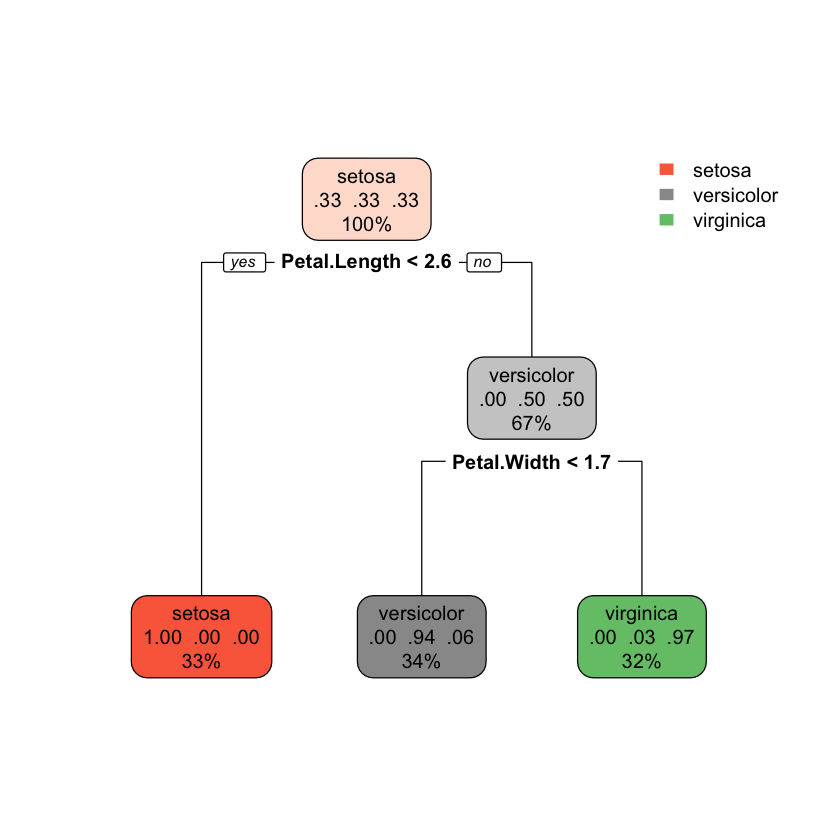

In [7]:
# 5. Visualizar el árbol
rpart.plot(modelo_rpart$finalModel)

In [8]:
# 6. Predicciones y evaluación en entrenamiento
pred_train <- predict(modelo_rpart, newdata = iris_train)
conf_train <- confusionMatrix(pred_train, iris_train$Species)

cat("\n--- MATRIZ DE CONFUSIÓN ENTRENAMIENTO ---\n")
print(conf_train$table)
cat("Precisión en entrenamiento:", conf_train$overall['Accuracy'], "\n")


--- MATRIZ DE CONFUSIÓN ENTRENAMIENTO ---
            Reference
Prediction   setosa versicolor virginica
  setosa         35          0         0
  versicolor      0         34         2
  virginica       0          1        33
Precisión en entrenamiento: 0.9714286 


In [9]:
# 7. Predicciones y evaluación en test
pred_test <- predict(modelo_rpart, newdata = iris_test)
conf_test <- confusionMatrix(pred_test, iris_test$Species)

cat("\n--- MATRIZ DE CONFUSIÓN TEST ---\n")
print(conf_test$table)
cat("Precisión en test:", conf_test$overall['Accuracy'], "\n")


--- MATRIZ DE CONFUSIÓN TEST ---
            Reference
Prediction   setosa versicolor virginica
  setosa         15          0         0
  versicolor      0         14         2
  virginica       0          1        13
Precisión en test: 0.9333333 


In [10]:
# 8. Métricas por clase
cat("\n--- MÉTRICAS POR CLASE (TEST) ---\n")
print(conf_test$byClass)


--- MÉTRICAS POR CLASE (TEST) ---
                  Sensitivity Specificity Pos Pred Value Neg Pred Value
Class: setosa       1.0000000   1.0000000      1.0000000      1.0000000
Class: versicolor   0.9333333   0.9333333      0.8750000      0.9655172
Class: virginica    0.8666667   0.9666667      0.9285714      0.9354839
                  Precision    Recall        F1 Prevalence Detection Rate
Class: setosa     1.0000000 1.0000000 1.0000000  0.3333333      0.3333333
Class: versicolor 0.8750000 0.9333333 0.9032258  0.3333333      0.3111111
Class: virginica  0.9285714 0.8666667 0.8965517  0.3333333      0.2888889
                  Detection Prevalence Balanced Accuracy
Class: setosa                0.3333333         1.0000000
Class: versicolor            0.3555556         0.9333333
Class: virginica             0.3111111         0.9166667


In [11]:
# 9. Graficar matrices de confusión con ggplot2
plot_confusion <- function(cm, title) {
  df <- as.data.frame(cm$table)
  ggplot(df, aes(x = Reference, y = Prediction, fill = Freq)) +
    geom_tile() +
    geom_text(aes(label = Freq), color = "white", size = 6) +
    scale_fill_gradient(low = "steelblue", high = "darkred") +
    labs(title = title, x = "Clase Real", y = "Clase Predicha") +
    theme_minimal()
}

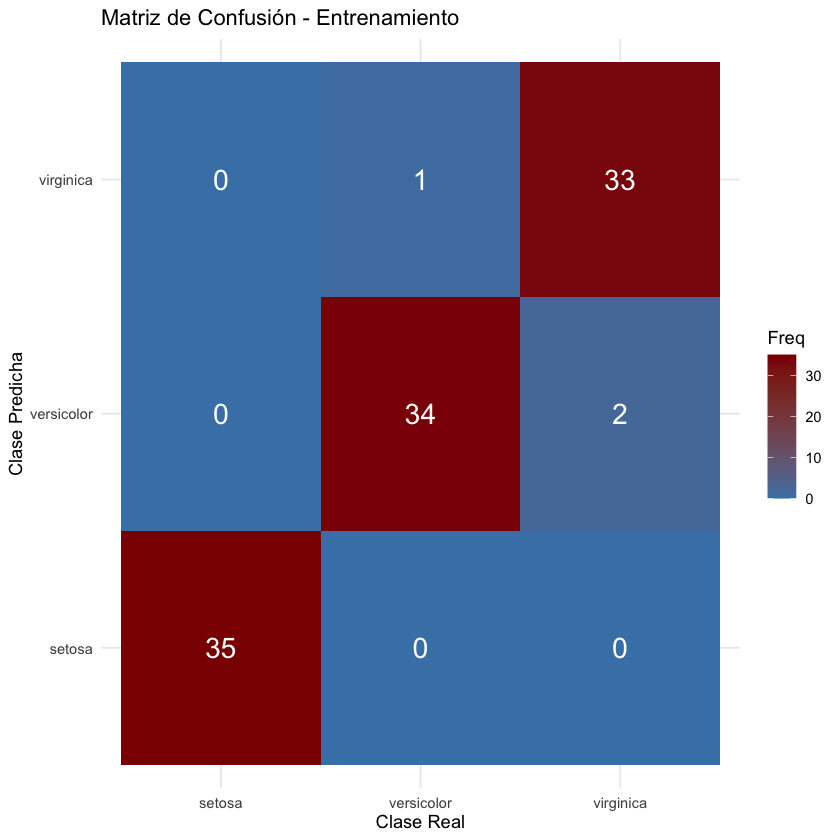

In [12]:
# Graficar entrenamiento
plot_confusion(conf_train, "Matriz de Confusión - Entrenamiento")

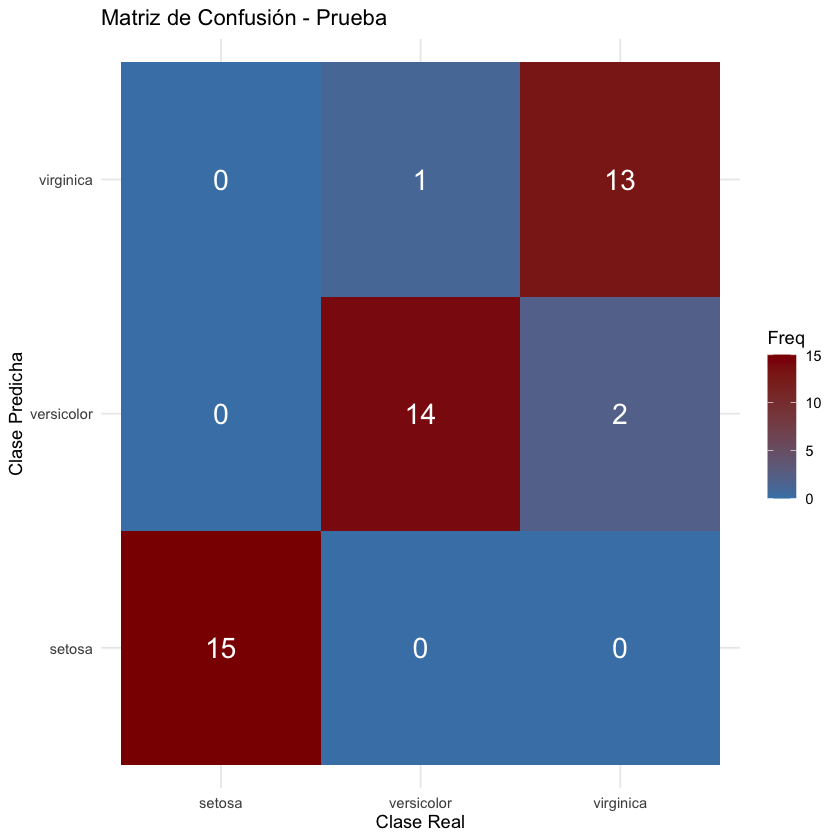

In [13]:
# Graficar prueba
plot_confusion(conf_test, "Matriz de Confusión - Prueba")

In [14]:
cat("\nImportancia de variables:\n")
print(varImp(modelo_rpart))


Importancia de variables:
rpart variable importance

             Overall
Petal.Width   100.00
Petal.Length   96.29
Sepal.Length   41.60
Sepal.Width     0.00
